# 04 – Baseline ML truyền thống (TF-IDF + LR / SVM / NB)

Mục tiêu: dựng mốc so sánh cho BiLSTM và PhoBERT trên UIT-VSFC (3 lớp negative / neutral / positive), metric chính Macro-F1.

Quy tắc xuyên suốt notebook:
- Chọn mô hình và siêu tham số **chỉ dựa trên tập dev**.
- Tập **test chỉ chấm một lần**, sau khi đã chốt mô hình.
- Mọi bảng và ma trận nhầm lẫn dùng cùng thứ tự lớp: negative, neutral, positive.

## 1. Nạp dữ liệu và kiểm tra

Đọc `data_clean.csv`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, json
import numpy as np
import pandas as pd

PROJECT     = '/content/drive/MyDrive/project1_vsfc'
DATA_DIR    = f'{PROJECT}/data'
RESULTS_DIR = f'{PROJECT}/results'

SEED    = 42
LABELS  = ['negative', 'neutral', 'positive']     # thứ tự cố định cho mọi bảng và ma trận nhầm lẫn
ID2NAME = {0: 'negative', 1: 'neutral', 2: 'positive'}

df = pd.read_csv(f'{DATA_DIR}/data_clean.csv', encoding='utf-8-sig', keep_default_na=False)
tr = df[df['split'] == 'train'].reset_index(drop=True)
dv = df[df['split'] == 'dev'].reset_index(drop=True)
te = df[df['split'] == 'test'].reset_index(drop=True)

y_tr, y_dv, y_te = tr['sentiment'].values, dv['sentiment'].values, te['sentiment'].values
cnt = pd.crosstab(df['split'], df['sentiment_name'])[LABELS].loc[['train', 'dev', 'test']]
pct = (cnt.div(cnt.sum(axis=1), axis=0) * 100).round(1)

Mounted at /content/drive


## 2. Hàm đánh giá chung

Định nghĩa một lần, dùng cho mọi mô hình ở các ô sau để số liệu so sánh được với nhau:

- `evaluate`: trả về Macro-F1 (metric chính), Accuracy, và Precision / Recall / F1 từng lớp.
- `show_report`: in báo cáo chi tiết theo từng lớp.
- `plot_cm`: vẽ ma trận nhầm lẫn (số câu và tỉ lệ theo hàng), thứ tự lớp cố định.
- `log_result`: gom kết quả của mọi cấu hình vào một danh sách.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

LABEL_IDS = [0, 1, 2]          # tương ứng LABELS = negative, neutral, positive
RESULTS = []

def evaluate(y_true, y_pred, name='', split=''):
    """Trả về dict số liệu: Macro-F1 (chính), Accuracy, P/R/F1 từng lớp."""
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABEL_IDS, zero_division=0)
    row = {'model': name, 'split': split,
           'macro_f1': f1_score(y_true, y_pred, average='macro', labels=LABEL_IDS, zero_division=0),
           'accuracy': accuracy_score(y_true, y_pred)}
    for i, lab in enumerate(LABELS):
        row[f'P_{lab}'], row[f'R_{lab}'], row[f'F1_{lab}'] = p[i], r[i], f[i]
    return row

def log_result(row, **extra):
    """Thêm một kết quả vào RESULTS (extra: tham số, thời gian chạy, ...)."""
    RESULTS.append({**row, **extra})
    return row

def show_report(y_true, y_pred):
    print(classification_report(y_true, y_pred, labels=LABEL_IDS,
                                target_names=LABELS, digits=4, zero_division=0))

def plot_cm(y_true, y_pred, title='', path=None):
    """Ma trận nhầm lẫn: số câu (trên) và tỉ lệ % theo hàng (dưới, hàng = nhãn thật)."""
    cm = confusion_matrix(y_true, y_pred, labels=LABEL_IDS)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f'{cm[i, j]}\n({cm_pct[i, j]:.1f}%)' for j in range(3)] for i in range(3)])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False,
                xticklabels=LABELS, yticklabels=LABELS)
    plt.xlabel('Dự đoán'); plt.ylabel('Nhãn thật'); plt.title(title)
    if path:
        plt.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()

## 3. Mốc: TF-IDF + Logistic Regression

Mô hình đơn giản nhất làm điểm xuất phát: TF-IDF trên từ đơn (unigram) của `text_clean`, phân loại bằng Logistic Regression. Mọi cấu hình ở các ô sau sẽ so với mốc này.

Hai điểm cần giữ đúng:
- Bộ vector hóa và bộ phân loại bọc trong một `Pipeline`, chỉ `fit` trên **train**, nên từ vựng và IDF không bị rò rỉ từ dev/test.
- `token_pattern` giữ cả từ một ký tự ("ạ", "ô") và bỏ dấu câu; các từ phủ định ("không", "chưa") và từ chỉ mức độ ("rất") được giữ nguyên, không bỏ stopword.

So sánh hai biến thể về trọng số lớp, vì neutral chỉ chiếm ~4%:
1. Không dùng class weight.
2. `class_weight='balanced'` (lớp ít được phạt nặng hơn khi đoán sai).

Chỉ chấm trên **dev**. Hàm `run_sk` được định nghĩa ở đây để tái sử dụng.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

TOKEN = r'(?u)\b\w+\b'      # giữ cả từ 1 ký tự, bỏ dấu câu

def run_sk(name, vec, clf, text_col='text_clean', verbose=True, **extra):
    """Fit trên train, chấm trên dev, ghi vào RESULTS. Trả về (pipeline, dòng kết quả)."""
    pipe = Pipeline([('vec', vec), ('clf', clf)])
    t0 = time.time()
    pipe.fit(tr[text_col], y_tr)
    fit_s = time.time() - t0
    pred = pipe.predict(dv[text_col])
    row = evaluate(y_dv, pred, name, 'dev')
    log_result(row, text_col=text_col, fit_sec=round(fit_s, 1), **extra)
    if verbose:
        print(f"{name:35s} Macro-F1 = {row['macro_f1']:.4f} | Acc = {row['accuracy']:.4f} "
              f"| F1 neutral = {row['F1_neutral']:.4f} | fit {fit_s:.1f}s")
    return pipe, row

def make_vec(**kw):
    base = dict(token_pattern=TOKEN, lowercase=True, sublinear_tf=True, min_df=2)
    base.update(kw)
    return TfidfVectorizer(**base)

def make_lr(cw=None, C=1.0):
    return LogisticRegression(C=C, class_weight=cw, max_iter=2000, random_state=SEED)

# --- Mốc: unigram, text_clean ---
pipes = {}
pipes['LR'],          r1 = run_sk('TFIDF-uni + LR',          make_vec(ngram_range=(1, 1)), make_lr(None),
                                  model_family='LR', ngram='word(1,1)', class_weight='none')
pipes['LR-balanced'], r2 = run_sk('TFIDF-uni + LR (balanced)', make_vec(ngram_range=(1, 1)), make_lr('balanced'),
                                  model_family='LR', ngram='word(1,1)', class_weight='balanced')

print('\nKích thước từ vựng:', len(pipes['LR'].named_steps['vec'].vocabulary_))

# --- Báo cáo chi tiết từng lớp trên dev ---
for key in ['LR', 'LR-balanced']:
    print(f'\n=== {key} (dev) ===')
    show_report(y_dv, pipes[key].predict(dv['text_clean']))

TFIDF-uni + LR                      Macro-F1 = 0.7023 | Acc = 0.9078 | F1 neutral = 0.2558 | fit 0.5s
TFIDF-uni + LR (balanced)           Macro-F1 = 0.7182 | Acc = 0.8490 | F1 neutral = 0.3704 | fit 0.5s

Kích thước từ vựng: 1484

=== LR (dev) ===
              precision    recall  f1-score   support

    negative     0.8862    0.9504    0.9172       705
     neutral     0.8462    0.1507    0.2558        73
    positive     0.9287    0.9391    0.9339       805

    accuracy                         0.9078      1583
   macro avg     0.8870    0.6801    0.7023      1583
weighted avg     0.9060    0.9078    0.8952      1583


=== LR-balanced (dev) ===
              precision    recall  f1-score   support

    negative     0.9088    0.8340    0.8698       705
     neutral     0.2538    0.6849    0.3704        73
    positive     0.9553    0.8770    0.9145       805

    accuracy                         0.8490      1583
   macro avg     0.7060    0.7987    0.7182      1583
weighted avg     0

## 4. Thêm SVM và Naive Bayes

Giữ nguyên đầu vào của mốc (TF-IDF unigram trên `text_clean`) để chỉ thay đổi **bộ phân loại**, từ đó so sánh công bằng với LR ở ô 3.

- **Linear SVM (`LinearSVC`)**: thường mạnh nhất trên văn bản TF-IDF. Chạy có và không `class_weight='balanced'`.
- **Naive Bayes**: nhanh, hay dùng làm mốc cho văn bản. Naive Bayes không có `class_weight`, nên dùng hai cách tương đương:
  - `MultinomialNB(fit_prior=False)`: bỏ prior theo tần suất lớp, coi các lớp như nhau.
  - `ComplementNB`: biến thể thiết kế cho dữ liệu lệch lớp.
  - `MultinomialNB` mặc định để đối chiếu.

Tất cả dùng tham số mặc định hợp lý (`C=1`, `alpha=1`), chưa tinh chỉnh; tinh chỉnh nhỏ trên dev để dành cho ô 7. Chỉ chấm trên **dev**. Cuối ô in bảng gộp mọi cấu hình đã chạy (gồm mốc LR ở ô 3), xếp theo Macro-F1 kèm Precision/Recall của neutral để thấy mô hình nào đang đánh đổi như thế nào.

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB

def make_svm(cw=None, C=1.0):
    return LinearSVC(C=C, class_weight=cw, max_iter=5000, random_state=SEED)

uni = dict(ngram_range=(1, 1))

# --- Linear SVM ---
pipes['SVM'],          _ = run_sk('TFIDF-uni + SVM',            make_vec(**uni), make_svm(None),
                                  model_family='SVM', ngram='word(1,1)', class_weight='none')
pipes['SVM-balanced'], _ = run_sk('TFIDF-uni + SVM (balanced)', make_vec(**uni), make_svm('balanced'),
                                  model_family='SVM', ngram='word(1,1)', class_weight='balanced')

# --- Naive Bayes ---
pipes['NB'],           _ = run_sk('TFIDF-uni + MultinomialNB',               make_vec(**uni), MultinomialNB(alpha=1.0),
                                  model_family='NB', ngram='word(1,1)', class_weight='none')
pipes['NB-noprior'],   _ = run_sk('TFIDF-uni + MultinomialNB (fit_prior=F)', make_vec(**uni), MultinomialNB(alpha=1.0, fit_prior=False),
                                  model_family='NB', ngram='word(1,1)', class_weight='uniform-prior')
pipes['CNB'],          _ = run_sk('TFIDF-uni + ComplementNB',                make_vec(**uni), ComplementNB(alpha=1.0),
                                  model_family='NB', ngram='word(1,1)', class_weight='complement')

# --- Bảng gộp tất cả cấu hình đã chạy trên dev ---
res = pd.DataFrame(RESULTS)
res = res[res['split'] == 'dev']
cols = ['model', 'macro_f1', 'accuracy', 'P_neutral', 'R_neutral', 'F1_neutral',
        'F1_negative', 'F1_positive', 'fit_sec']
print('\nTất cả cấu hình trên dev, xếp theo Macro-F1:')
print(res[cols].sort_values('macro_f1', ascending=False).round(4).to_string(index=False))

# --- Báo cáo chi tiết của mô hình mới tốt nhất ---
new = res[res['model'].str.contains('SVM|NB')].sort_values('macro_f1', ascending=False)
best_name = new.iloc[0]['model']
key = {'TFIDF-uni + SVM': 'SVM', 'TFIDF-uni + SVM (balanced)': 'SVM-balanced',
       'TFIDF-uni + MultinomialNB': 'NB', 'TFIDF-uni + MultinomialNB (fit_prior=F)': 'NB-noprior',
       'TFIDF-uni + ComplementNB': 'CNB'}[best_name]
print(f'\n=== Mô hình mới tốt nhất: {best_name} (dev) ===')
show_report(y_dv, pipes[key].predict(dv['text_clean']))


TFIDF-uni + SVM                     Macro-F1 = 0.7072 | Acc = 0.9059 | F1 neutral = 0.2708 | fit 0.3s
TFIDF-uni + SVM (balanced)          Macro-F1 = 0.7604 | Acc = 0.8958 | F1 neutral = 0.4358 | fit 0.3s
TFIDF-uni + MultinomialNB           Macro-F1 = 0.5863 | Acc = 0.8591 | F1 neutral = 0.0000 | fit 0.1s
TFIDF-uni + MultinomialNB (fit_prior=F) Macro-F1 = 0.6705 | Acc = 0.8351 | F1 neutral = 0.2822 | fit 0.1s
TFIDF-uni + ComplementNB            Macro-F1 = 0.6083 | Acc = 0.8553 | F1 neutral = 0.0732 | fit 0.1s

Tất cả cấu hình trên dev, xếp theo Macro-F1:
                                  model  macro_f1  accuracy  P_neutral  R_neutral  F1_neutral  F1_negative  F1_positive  fit_sec
             TFIDF-uni + SVM (balanced)    0.7604    0.8958     0.3679     0.5342      0.4358       0.9116       0.9338      0.3
              TFIDF-uni + LR (balanced)    0.7182    0.8490     0.2538     0.6849      0.3704       0.8698       0.9145      0.5
                        TFIDF-uni + SVM    0.7072    

In [ ]:
def log_result(row, **extra):
    """Ghi kết quả; nếu cùng (model, split) đã có thì thay bằng bản mới."""
    global RESULTS
    new = {**row, **extra}
    RESULTS = [r for r in RESULTS if not (r['model'] == new['model'] and r['split'] == new['split'])]
    RESULTS.append(new)
    return row

_seen = {}
for r in RESULTS:
    _seen[(r['model'], r['split'])] = r
RESULTS = list(_seen.values())
print(len(RESULTS), 'cấu hình')

7 cấu hình


## 5. Chấm test (một lần duy nhất)

Chọn mô hình có **Macro-F1 cao nhất trên dev** ở ô 4, rồi chấm trên **test đúng một lần**. Sau bước này không quay lại chỉnh mô hình hay tham số.

- `NAME2KEY` : ánh xạ tên mô hình trong bảng kết quả về pipeline đã fit trong `pipes`.
- Việc chọn mô hình **chỉ dựa trên dev**; test chỉ dùng để báo cáo.
- Kết quả được lưu vào `results/`:
  - `ml_test_metrics.csv` : Macro-F1, Accuracy, Precision / Recall / F1 từng lớp.
  - `fig_cm_ml_best_test.png` : ma trận nhầm lẫn (thứ tự lớp: negative, neutral, positive).
- Ô cuối in số câu neutral bị đoán sai, để ghi vào README.

Lưu ý: test chỉ có 167 câu neutral nên F1 neutral dao động khá mạnh; dev chỉ có 73 câu neutral nên điểm dev thường lạc quan hơn hoặc lệch so với test.

Mô hình được chọn (theo dev): TFIDF-uni + SVM (balanced)

TEST | Macro-F1 = 0.7399 | Acc = 0.8756 | F1 neutral = 0.4119

              precision    recall  f1-score   support

    negative     0.8847    0.9099    0.8971      1409
     neutral     0.3762    0.4551    0.4119       167
    positive     0.9333    0.8893    0.9108      1590

    accuracy                         0.8756      3166
   macro avg     0.7314    0.7514    0.7399      3166
weighted avg     0.8823    0.8756    0.8784      3166



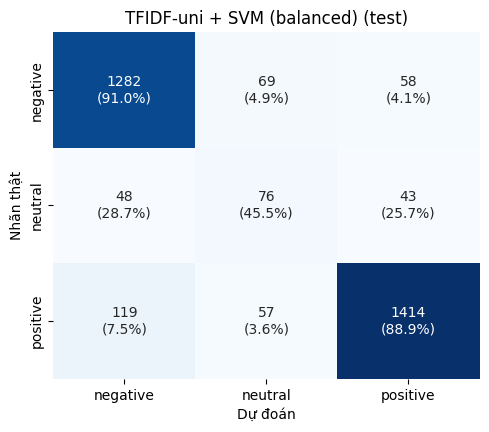

Neutral bị đoán sai: 91/167


In [ ]:
# 5. Chấm test đúng một lần cho mô hình có Macro-F1 dev cao nhất
NAME2KEY = {
    'TFIDF-uni + LR': 'LR',
    'TFIDF-uni + LR (balanced)': 'LR-balanced',
    'TFIDF-uni + SVM': 'SVM',
    'TFIDF-uni + SVM (balanced)': 'SVM-balanced',
    'TFIDF-uni + MultinomialNB': 'NB',
    'TFIDF-uni + MultinomialNB (fit_prior=F)': 'NB-noprior',
    'TFIDF-uni + ComplementNB': 'CNB',
}

dev_tab = pd.DataFrame(RESULTS)
dev_tab = dev_tab[dev_tab['split'] == 'dev'].sort_values('macro_f1', ascending=False)
best_name = dev_tab.iloc[0]['model']          # chọn CHỈ dựa trên dev
best_pipe = pipes[NAME2KEY[best_name]]
print(f'Mô hình được chọn (theo dev): {best_name}')

pred_te = best_pipe.predict(te['text_clean'])
row_te = evaluate(y_te, pred_te, best_name, 'test')
log_result(row_te, text_col='text_clean')

print(f"\nTEST | Macro-F1 = {row_te['macro_f1']:.4f} | Acc = {row_te['accuracy']:.4f} "
      f"| F1 neutral = {row_te['F1_neutral']:.4f}\n")
show_report(y_te, pred_te)

# Lưu kết quả
os.makedirs(RESULTS_DIR, exist_ok=True)
pd.DataFrame([row_te]).round(4).to_csv(
    f'{RESULTS_DIR}/ml_test_metrics.csv', index=False, encoding='utf-8-sig')
plot_cm(y_te, pred_te, title=f'{best_name} (test)',
        path=f'{RESULTS_DIR}/fig_cm_ml_best_test.png')

# Số câu neutral bị đoán sai, để ghi vào README
n_neu = int((y_te == 1).sum())
n_neu_wrong = int(((y_te == 1) & (pred_te != 1)).sum())
print(f'Neutral bị đoán sai: {n_neu_wrong}/{n_neu}')